In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,VotingClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from xgboost import XGBClassifier
import pickle 
import os

In [2]:
# Load the dataset
df = pd.read_csv('../data/dataset.csv')

# How many rows and columns?
print(" Dataset Shape:")
print(f"   Rows: {df.shape[0]}")
print(f"   Columns: {df.shape[1]}")
print(df.shape)

# First 5 rows
print("\n First 5 rows:")
df.head()

 Dataset Shape:
   Rows: 11430
   Columns: 89
(11430, 89)

 First 5 rows:


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [3]:
from tranco import Tranco

t = Tranco(cache=True, cache_dir='.tranco')
latest_list = t.list()

print("Google rank:", latest_list.rank("google.com"))
print("GitHub rank:", latest_list.rank("github.com"))
print("Random unknown domain:", latest_list.rank("totally-fake-nonexistent-site12345.com"))

Google rank: 1
GitHub rank: 30
Random unknown domain: -1


In [4]:
import tldextract
def get_web_traffic_score(url,trance_list):
    try:
        extracted=tldextract.extract(url)
        domain=f"{extracted.domain}.{extracted.suffix}"
        rank=trance_list.rank(domain)
        return rank
    except Exception:
        return -1
    
sample_urls=df['url'].head(5).tolist()
for url in sample_urls:
    score=get_web_traffic_score(url, latest_list)
    print(f'{url[:50]:50}   rank{score}')

http://www.crestonwood.com/router.php                rank-1
http://shadetreetechnology.com/V4/validation/a111a   rank-1
https://support-appleld.com.secureupdate.duilawyer   rank-1
http://rgipt.ac.in                                   rank549807
http://www.iracing.com/tracks/gateway-motorsports-   rank13288


In [5]:
df['web_traffic_new'] = df['url'].apply(lambda url: get_web_traffic_score(url, latest_list))

print("Done!")
print(df['web_traffic_new'].describe())
print("\nHow many got rank -1 (unranked):", (df['web_traffic_new'] == -1).sum())
print("How many got a real rank:", (df['web_traffic_new'] != -1).sum())

Done!
count     11430.000000
mean      49783.389151
std      149895.752359
min          -1.000000
25%          -1.000000
50%          -1.000000
75%        6931.000000
max      999271.000000
Name: web_traffic_new, dtype: float64

How many got rank -1 (unranked): 5881
How many got a real rank: 5549


In [6]:
#Check correlation between unranked status and phishing label
unranked = df[df['web_traffic_new'] == -1]
ranked = df[df['web_traffic_new'] != -1]

print("Among UNRANKED domains:")
print(unranked['status'].value_counts())
print(f"\n% phishing among unranked: {(unranked['status']=='phishing').mean()*100:.1f}%")

print("\nAmong RANKED domains:")
print(ranked['status'].value_counts())
print(f"\n% phishing among ranked: {(ranked['status']=='phishing').mean()*100:.1f}%")

Among UNRANKED domains:
status
phishing      3846
legitimate    2035
Name: count, dtype: int64

% phishing among unranked: 65.4%

Among RANKED domains:
status
legitimate    3680
phishing      1869
Name: count, dtype: int64

% phishing among ranked: 33.7%


In [7]:
# How many phishing vs legitimate?
print(" Label Distribution:")
print(df['status'].value_counts())
print(df['web_traffic'].value_counts())

#change of web_traffic column
df['web_traffic'] = df['web_traffic_new']
df = df.drop(columns=['web_traffic_new'])  #delete the old name duplicate
print(df['web_traffic'].describe())
print(f"\nUnranked (-1) count: {(df['web_traffic'] == -1).sum()}")

# Any missing values?
print("\n Missing Values:")
print(df.isnull().sum().sum(), "missing values in total")

 Label Distribution:
status
legitimate    5715
phishing      5715
Name: count, dtype: int64
web_traffic
0          4444
5707171     176
12          163
1           148
5697976      91
           ... 
33758         1
3050940       1
788648        1
3980          1
2455493       1
Name: count, Length: 4744, dtype: int64
count     11430.000000
mean      49783.389151
std      149895.752359
min          -1.000000
25%          -1.000000
50%          -1.000000
75%        6931.000000
max      999271.000000
Name: web_traffic, dtype: float64

Unranked (-1) count: 5881

 Missing Values:
0 missing values in total


In [8]:
print(f"Unranked (-1) count: {(df['web_traffic'] == -1).sum()}")
print(f"Ranked count: {(df['web_traffic'] != -1).sum()}")

Unranked (-1) count: 5881
Ranked count: 5549


In [ ]:
# Only these 3 are truly impossible to get for free/live:
# - web_traffic & page_rank: relied on Alexa, which shut down
# - google_index: would require scraping Google search (against ToS)
external_lookup_cols = [
    'page_rank', 'google_index'
]

# X = all columns except url, status, and the 3 truly unrecoverable columns
X = df.drop(columns=['url', 'status'] + external_lookup_cols)

# y = status column (what we want to predict)
y = df['status'].map({'legitimate': 0, 'phishing': 1})

print(" Features and labels prepared!")
print(f"   Total features: {X.shape[1]}")
print(f"   Total samples:  {X.shape[0]}")
print(f"\n   Legitimate (0): {(y==0).sum()}")
print(f"   Phishing   (1): {(y==1).sum()}")
print(f"\nDropped columns (truly unrecoverable): {external_lookup_cols}")
print(f"\nKept (recoverable via WHOIS/DNS): whois_registered_domain, domain_registration_length, domain_age, dns_record")
print(f"Recovered via Tranco API: web_traffic")

✅ Features and labels prepared!
   Total features: 85
   Total samples:  11430

   Legitimate (0): 5715
   Phishing   (1): 5715

Dropped columns (truly unrecoverable): ['page_rank', 'google_index']

Kept (recoverable via WHOIS/DNS): whois_registered_domain, domain_registration_length, domain_age, dns_record
Recovered via Tranco API: web_traffic


In [10]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
print(f"   Training samples: {len(X_train)}")
print(f"   Testing samples:  {len(X_test)}")

   Training samples: 9144
   Testing samples:  2286


In [11]:
from sklearn.neural_network import MLPClassifier
# Model 1 - Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Model 2 - XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

# Hybrid Model - combines both
hybrid_model = VotingClassifier(
    estimators=[
        ('random_forest', rf_model),
        ('xgboost', xgb_model)
    ],
    voting='soft'
)

# Train the model
hybrid_model.fit(X_train, y_train)

print(" Training complete!")

 Training complete!


In [12]:
# Make predictions on test data
y_pred = hybrid_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("="*45)
print("           MODEL RESULTS")
print("="*45)
print(f"  Accuracy: {accuracy * 100:.2f}%")
print("="*45)

# Detailed report
print("\n Detailed Report:")
print(classification_report(y_test, y_pred, 
      target_names=['Legitimate', 'Phishing']))

# Confusion matrix
print(" Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(f"  ✅ Correctly identified Legitimate: {cm[0][0]}")
print(f"  ✅ Correctly identified Phishing:   {cm[1][1]}")
print(f"  ❌ Legitimate wrongly flagged:      {cm[0][1]}")
print(f"  ❌ Phishing wrongly missed:         {cm[1][0]}")

           MODEL RESULTS
  Accuracy: 95.84%

 Detailed Report:
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1157
    Phishing       0.96      0.96      0.96      1129

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286

 Confusion Matrix:
  ✅ Correctly identified Legitimate: 1107
  ✅ Correctly identified Phishing:   1084
  ❌ Legitimate wrongly flagged:      50
  ❌ Phishing wrongly missed:         45


In [13]:
# Create models folder if it doesn't exist
os.makedirs('../models', exist_ok=True)

# Save the trained hybrid model
with open('../models/hybrid_model.pkl', 'wb') as f:
    pickle.dump(hybrid_model, f)

# Save feature names (needed later for prediction)
with open('../models/feature_names.pkl', 'wb') as f:
    pickle.dump(X.columns.tolist(), f)

print("Model saved to models/hybrid_model.pkl")
print("Feature names saved to models/feature_names.pkl")
print("\n Your hybrid model is ready to use!")

Model saved to models/hybrid_model.pkl
Feature names saved to models/feature_names.pkl

 Your hybrid model is ready to use!


In [14]:
import torch
from torch import nn
import torch.optim as optim 
from torch.utils.data import DataLoader,TensorDataset
from sklearn.preprocessing import StandardScaler
print(f"pytorch_version={torch.__version__}")

pytorch_version=2.12.1+cpu


In [15]:
X_train.shape

(9144, 85)

In [16]:
# Neural networks work better when all values are in same range
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

#convert the data to tensor
X_train_tensor=torch.FloatTensor(X_train_scaled)
X_test_tensor  = torch.FloatTensor(X_test_scaled)
y_train_tensor = torch.FloatTensor(y_train.values).reshape(-1, 1)
y_test_tensor  = torch.FloatTensor(y_test.values).reshape(-1, 1)

print(f"   X_train: {X_train_tensor.shape}")
print(f"   X_test:  {X_test_tensor.shape}")
print(f"   y_train: {y_train_tensor.shape}")
print(f"   y_test:  {y_test_tensor.shape}")

#use dataloader to fetch the data in small batches
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

train_dataloader=DataLoader(train_dataset,32,True)
test_dataloader=DataLoader(test_dataset,32,False)

print(f'length of train:{len(train_dataloader)}')
print(f'lenght of test:{len(test_dataloader)}')

   X_train: torch.Size([9144, 85])
   X_test:  torch.Size([2286, 85])
   y_train: torch.Size([9144, 1])
   y_test:  torch.Size([2286, 1])
length of train:286
lenght of test:72


C:\Users\dharam dutt\AppData\Local\Temp\ipykernel_4464\2472834307.py:9: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y_train_tensor = torch.FloatTensor(y_train.values).reshape(-1, 1)


In [17]:
torch.manual_seed(42)
class PhishingNN(nn.Module):
    def __init__(self,input_size):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )
    def forward(self,x):
        return self.layers(x)
  
input_size = X_train.shape[1]  
model = PhishingNN(input_size)
print(f"\n   Input features: {input_size}")
print(f"   Total parameters: {sum(p.numel() for p in model.parameters())}")


   Input features: 85
   Total parameters: 21377


In [18]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

Epoch [5/50]  Loss: 0.1637  Accuracy: 93.92%
Epoch [10/50]  Loss: 0.1280  Accuracy: 95.28%
Epoch [15/50]  Loss: 0.1069  Accuracy: 95.90%
Epoch [20/50]  Loss: 0.0920  Accuracy: 96.48%
Epoch [25/50]  Loss: 0.0814  Accuracy: 96.65%
Epoch [30/50]  Loss: 0.0735  Accuracy: 97.33%
Epoch [35/50]  Loss: 0.0677  Accuracy: 97.41%
Epoch [40/50]  Loss: 0.0610  Accuracy: 97.57%
Epoch [45/50]  Loss: 0.0612  Accuracy: 97.77%
Epoch [50/50]  Loss: 0.0517  Accuracy: 98.23%


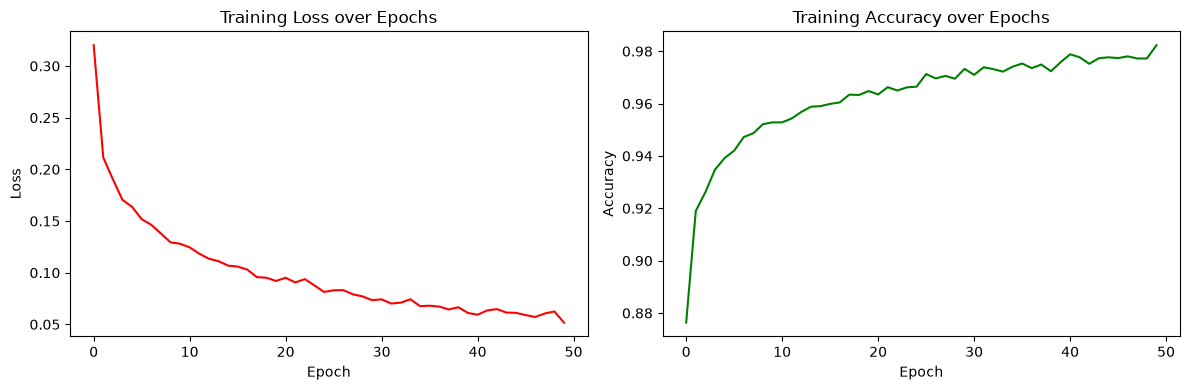

In [19]:
import matplotlib.pyplot as plt

torch.manual_seed(42)
epochs=50
loss_history = []
acc_history = []
for epoch in range(epochs):
    model.train()
    total_loss=0
    total_acc=0
    for batch,(batchX,y) in enumerate(train_dataloader):
        y_pred=model(batchX)
        loss=loss_fn(y_pred,y)
        total_loss+=loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #Accuracy: round probability to 0 or 1, then squeeze to match shape
        predicted_labels = torch.sigmoid(y_pred).round().squeeze()
        y_squeezed = y.squeeze()
        batch_acc = (predicted_labels == y_squeezed).float().mean().item()
        total_acc += batch_acc

        '''# accuracy_score needs numpy arrays, not tensors with gradients
        predicted_labels = y_pred.round().detach().numpy()
        true_labels = batch_y.numpy()
        
        batch_acc = accuracy_score(true_labels, predicted_labels)
        total_acc += batch_acc
        '''

    total_loss/=len(train_dataloader)
    total_acc/=len(train_dataloader)

    loss_history.append(total_loss)
    acc_history.append(total_acc)
    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{epochs}]  Loss: {total_loss:.4f}  Accuracy: {total_acc*100:.2f}%")

#plot the curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(loss_history, color='red')
axes[0].set_title('Training Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')

axes[1].plot(acc_history, color='green')
axes[1].set_title('Training Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')

plt.tight_layout()
plt.show()



In [20]:
# Check if any predictions are hitting exact 0 or 1
with torch.no_grad():
    sample_pred = model(X_train_tensor[:100])
    print("Min prediction:", sample_pred.min().item())
    print("Max prediction:", sample_pred.max().item())

Min prediction: -58.84537887573242
Max prediction: 346.6199645996094


In [21]:
torch.manual_seed(42)
with torch.inference_mode():
    model.eval()
    total_test_loss=0
    total_test_acc=0
    for batch,(batch_X,label) in enumerate(test_dataloader):
        test_logits=model(batch_X)
        test_prob=torch.sigmoid(test_logits)
        test_pred=test_prob.round().squeeze()
        test_loss=loss_fn(test_logits,label)
        total_test_loss+=test_loss.item()
        test_acc = (test_pred == label.squeeze()).float().mean().item()
        total_test_acc+=test_acc
print(test_logits.shape)
print(y_test.shape)
avg_loss=total_test_loss/len(test_dataloader)
avg_acc=total_test_acc/len(test_dataloader)

print(f'test_loss:{avg_loss:.4f}  test_acc{avg_acc*100:.2f}%')
    

torch.Size([14, 1])
(2286,)
test_loss:0.2177  test_acc94.95%


In [22]:
# Get predictions from sklearn hybrid (RF + XGBoost) — probabilities
sklearn_probs = hybrid_model.predict_proba(X_test)[:, 1]   # probability of phishing

# Get predictions from PyTorch model — probabilities
model.eval()
with torch.inference_mode():
    pytorch_logits = model(X_test_tensor)
    pytorch_probs = torch.sigmoid(pytorch_logits).squeeze().numpy()

# ── Combine: average the probabilities from all sources ──────
final_probs = (sklearn_probs + pytorch_probs) / 2
final_predictions = (final_probs > 0.5).astype(int)

# ── Evaluate final combined accuracy ──────────────────────────
final_accuracy = accuracy_score(y_test, final_predictions)

print("="*45)
print("     FINAL 3-MODEL HYBRID RESULTS")
print("="*45)
print(f"  Combined Accuracy: {final_accuracy*100:.2f}%")
print("="*45)

print("\n Detailed Report:")
print(classification_report(y_test, final_predictions, target_names=['Legitimate', 'Phishing']))

print("🔍 Confusion Matrix:")
cm = confusion_matrix(y_test, final_predictions)
print(f"   Correctly identified Legitimate: {cm[0][0]}")
print(f"   Correctly identified Phishing:   {cm[1][1]}")
print(f"   Legitimate wrongly flagged:      {cm[0][1]}")
print(f"   Phishing wrongly missed:         {cm[1][0]}")

     FINAL 3-MODEL HYBRID RESULTS
  Combined Accuracy: 95.67%

 Detailed Report:
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1157
    Phishing       0.95      0.96      0.96      1129

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286

🔍 Confusion Matrix:
   Correctly identified Legitimate: 1106
   Correctly identified Phishing:   1081
   Legitimate wrongly flagged:      51
   Phishing wrongly missed:         48


In [23]:
import os
import pickle
import torch

os.makedirs('../models', exist_ok=True)

# Save PyTorch model weights
torch.save(model.state_dict(), '../models/pytorch_model.pth')

# Save the scaler (used to preprocess features before feeding to PyTorch model)
with open('../models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print(" PyTorch model saved to models/pytorch_model.pth")
print(" Scaler saved to models/scaler.pkl")

# Quick check - list everything in models folder
print("\n Current files in models/ folder:")
for file in os.listdir('../models'):
    print(f"   {file}")

 PyTorch model saved to models/pytorch_model.pth
 Scaler saved to models/scaler.pkl

 Current files in models/ folder:
   feature_names.pkl
   hybrid_model.pkl
   pytorch_model.pth
   scaler.pkl


In [24]:
print(X.columns.tolist())
print(X.shape)

['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks', 'nb_extCSS', 'ratio_intR